## 1. Setup and Data Loading

In [1]:
# Import required libraries
import sys
from pathlib import Path

# Add src to path
sys.path.insert(0, str(Path().absolute().parent / 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from sklearn.model_selection import train_test_split

# Import project modules
from mediwatch.data.preprocess import PreprocessingArtifacts
from mediwatch.models.train import train_model, train_all_baselines, get_baseline_models
from mediwatch.models.evaluate import evaluate_model, compare_models, print_evaluation_report
from mediwatch.models.tune import run_hpo, tune_multiple_models
from mediwatch.registry.mlflow_registry import (
    setup_mlflow, get_best_run, compare_runs, register_model, promote_model_to_production
)

import warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


### Load Preprocessed Data

In [2]:
# Load train and test data
data_dir = Path('../data/processed')

train_df = pd.read_csv(data_dir / 'train.csv')
test_df = pd.read_csv(data_dir / 'test.csv')

print(f"Train set: {train_df.shape}")
print(f"Test set: {test_df.shape}")

# Load preprocessing artifacts
artifacts = PreprocessingArtifacts.load(data_dir / 'preprocessing_artifacts.pkl')
print(f"\nPreprocessing artifacts loaded")
print(f"Target column: {artifacts.metadata['target_col']}")
print(f"Number of features: {artifacts.metadata['n_features']}")

Train set: (81412, 25)
Test set: (20354, 25)

Preprocessing artifacts loaded
Target column: readmitted
Number of features: 24


### Prepare Features and Target

In [3]:
# Get target column name
target_col = artifacts.metadata['target_col']

# Separate features and target
X_train = train_df.drop(columns=[target_col])
y_train = train_df[target_col]

X_test = test_df.drop(columns=[target_col])
y_test = test_df[target_col]

print(f"Training features: {X_train.shape}")
print(f"Training target: {y_train.shape}")
print(f"\nTest features: {X_test.shape}")
print(f"Test target: {y_test.shape}")

# Check class distribution
print(f"\nTarget distribution (train):")
print(y_train.value_counts())
print(f"\nTarget distribution (%):")
print(y_train.value_counts(normalize=True) * 100)

Training features: (81412, 24)
Training target: (81412,)

Test features: (20354, 24)
Test target: (20354,)

Target distribution (train):
readmitted
2    43891
1    28436
0     9085
Name: count, dtype: int64

Target distribution (%):
readmitted
2    53.912200
1    34.928512
0    11.159289
Name: proportion, dtype: float64


## 2. MLflow Setup

In [4]:
# Setup MLflow
# Note: Start MLflow server first with: python scripts/setup_mlflow.py --action start
# Or run in background: mlflow server --host 127.0.0.1 --port 5000

MLFLOW_TRACKING_URI = "http://127.0.0.1:5000"
EXPERIMENT_NAME = "mediwatch-readmission"

try:
    experiment_id = setup_mlflow(
        tracking_uri=MLFLOW_TRACKING_URI,
        experiment_name=EXPERIMENT_NAME
    )
    print(f"✓ MLflow configured")
    print(f"  Tracking URI: {MLFLOW_TRACKING_URI}")
    print(f"  Experiment: {EXPERIMENT_NAME}")
    print(f"  Experiment ID: {experiment_id}")
    print(f"\nAccess MLflow UI at: {MLFLOW_TRACKING_URI}")
except Exception as e:
    print(f"Warning: Could not connect to MLflow server: {e}")
    print(f"\nTo start MLflow server, run in a separate terminal:")
    print(f"  python scripts/setup_mlflow.py --action start")
    print(f"\nContinuing without MLflow tracking...")

✓ MLflow configured
  Tracking URI: http://127.0.0.1:5000
  Experiment: mediwatch-readmission
  Experiment ID: 1

Access MLflow UI at: http://127.0.0.1:5000


## 3. Baseline Models Training

In [5]:
# Reload modules to pick up CatBoost removal
import importlib
import sys

if 'mediwatch.models.train' in sys.modules:
    importlib.reload(sys.modules['mediwatch.models.train'])
    from mediwatch.models.train import train_model, train_all_baselines, get_baseline_models

# Check available models (CatBoost removed due to sklearn compatibility issues)
available_models = get_baseline_models()
print(f"Available baseline models: {list(available_models.keys())}")
print(f"\nNote: CatBoost has been removed from the project due to sklearn compatibility issues.")

Available baseline models: ['logistic_regression', 'random_forest', 'gradient_boosting', 'xgboost', 'lightgbm']

Note: CatBoost has been removed from the project due to sklearn compatibility issues.


### Train Individual Models

In [6]:
# Train Logistic Regression
print("Training Logistic Regression...")
lr_artifacts = train_model(
    x_train=X_train,
    y_train=y_train,
    model_name="logistic_regression",
    use_scaling=True,
    track_mlflow=False,  # Disabled MLflow tracking
    experiment_name=EXPERIMENT_NAME
)

# Evaluate on test set
lr_metrics = evaluate_model(
    pipeline=lr_artifacts.pipeline,
    x_test=X_test,
    y_test=y_test,
    track_mlflow=False  # Disabled MLflow tracking
)

print_evaluation_report(lr_metrics, "Logistic Regression")

Training Logistic Regression...
✓ Trained logistic_regression in 0.18s
Logistic Regression Evaluation Report

Overall Metrics:
  Accuracy:  0.1333
  Precision: 0.1195
  Recall:    0.1333
  F1 Score:  0.0795
  ROC AUC:   0.6336

Confusion Matrix:
[[1901  371    0]
 [6296  813    0]
 [9515 1458    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.11      0.84      0.19      2272
           1       0.31      0.11      0.17      7109
           2       0.00      0.00      0.00     10973

    accuracy                           0.13     20354
   macro avg       0.14      0.32      0.12     20354
weighted avg       0.12      0.13      0.08     20354



In [7]:
# Train Random Forest
print("Training Random Forest...")
rf_artifacts = train_model(
    x_train=X_train,
    y_train=y_train,
    model_name="random_forest",
    use_scaling=False,  # Tree-based models don't need scaling
    track_mlflow=False,  # Disabled MLflow tracking
    experiment_name=EXPERIMENT_NAME
)

# Evaluate
rf_metrics = evaluate_model(
    pipeline=rf_artifacts.pipeline,
    x_test=X_test,
    y_test=y_test,
    track_mlflow=False  # Disabled MLflow tracking
)

print_evaluation_report(rf_metrics, "Random Forest")

Training Random Forest...
✓ Trained random_forest in 0.67s
Random Forest Evaluation Report

Overall Metrics:
  Accuracy:  0.1265
  Precision: 0.0830
  Recall:    0.1265
  F1 Score:  0.0606
  ROC AUC:   0.6595

Confusion Matrix:
[[2049  223    0]
 [6583  526    0]
 [9103 1870    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.12      0.90      0.20      2272
           1       0.20      0.07      0.11      7109
           2       0.00      0.00      0.00     10973

    accuracy                           0.13     20354
   macro avg       0.11      0.33      0.10     20354
weighted avg       0.08      0.13      0.06     20354



In [8]:
# Train XGBoost (if available)
try:
    print("Training XGBoost...")
    xgb_artifacts = train_model(
        x_train=X_train,
        y_train=y_train,
        model_name="xgboost",
        use_scaling=False,
        track_mlflow=False,  # Disabled MLflow tracking
        experiment_name=EXPERIMENT_NAME
    )
    
    xgb_metrics = evaluate_model(
        pipeline=xgb_artifacts.pipeline,
        x_test=X_test,
        y_test=y_test,
        track_mlflow=False  # Disabled MLflow tracking
    )
    
    print_evaluation_report(xgb_metrics, "XGBoost")
    
except Exception as e:
    print(f"XGBoost not available: {e}")

Training XGBoost...
✓ Trained xgboost in 0.89s
XGBoost Evaluation Report

Overall Metrics:
  Accuracy:  0.2712
  Precision: 0.1272
  Recall:    0.2712
  F1 Score:  0.1731
  ROC AUC:   0.6757

Confusion Matrix:
[[ 816 1456    0]
 [2405 4704    0]
 [2279 8694    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.15      0.36      0.21      2272
           1       0.32      0.66      0.43      7109
           2       0.00      0.00      0.00     10973

    accuracy                           0.27     20354
   macro avg       0.16      0.34      0.21     20354
weighted avg       0.13      0.27      0.17     20354



### Train All Baseline Models

In [9]:
# Train all available baseline models
baseline_results = train_all_baselines(
    x_train=X_train,
    y_train=y_train,
    use_scaling=True,  # Will be applied selectively based on model type
    track_mlflow=False,  # Disabled MLflow tracking
    experiment_name=EXPERIMENT_NAME
)

Training 5 baseline models...

Training logistic_regression...
✓ Trained logistic_regression in 0.16s

Training random_forest...
✓ Trained random_forest in 0.62s

Training gradient_boosting...
✓ Trained gradient_boosting in 52.08s

Training xgboost...
✓ Trained xgboost in 0.92s

Training lightgbm...
✓ Trained lightgbm in 1.88s

Completed training 5/5 models


## 4. Model Comparison

In [10]:
# Evaluate all models on test set
pipelines = {name: artifacts.pipeline for name, artifacts in baseline_results.items()}

comparison_df = compare_models(
    models=pipelines,
    x_test=X_test,
    y_test=y_test
)

print("\nModel Comparison:")
display(comparison_df)


Model Comparison:


,model,accuracy,precision,recall,f1,roc_auc,avg_precision
2,gradient_boosting,0.271888,0.127514,0.271888,0.173510,0.675295,None
3,xgboost,0.271200,0.127168,0.271200,0.173051,0.675719,None
4,lightgbm,0.149062,0.099959,0.149062,0.096290,0.669520,None
0,logistic_regression,0.133340,0.119458,0.133340,0.079478,0.633604,None
1,random_forest,0.126314,0.082914,0.126314,0.060579,0.659436,None


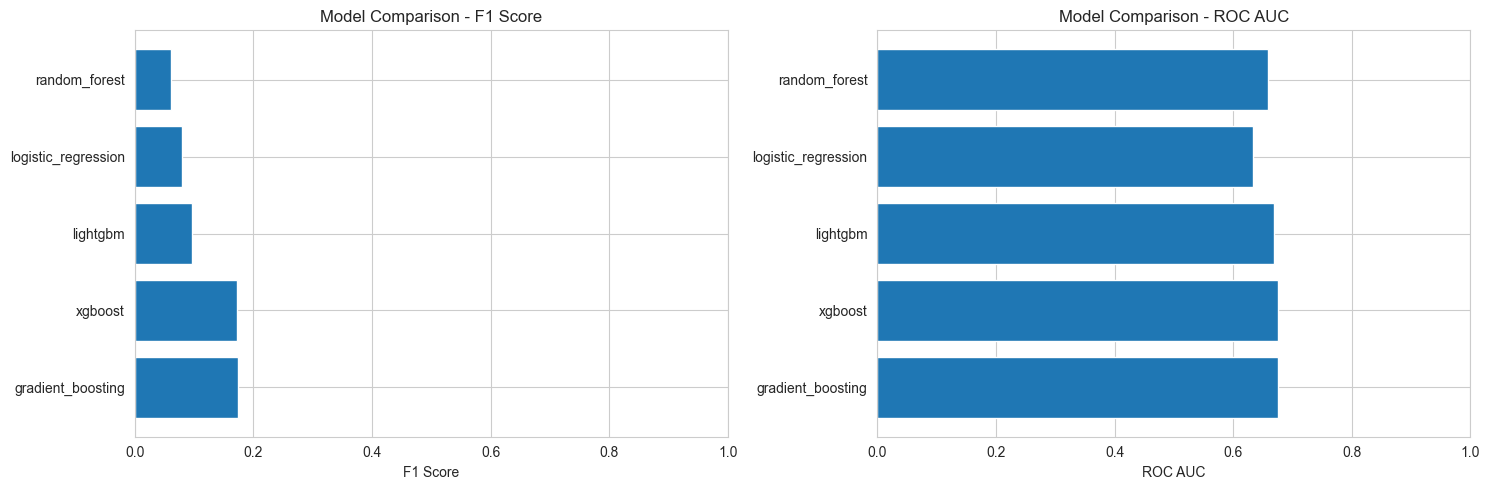

In [11]:
# Visualize comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# F1 Score comparison
axes[0].barh(comparison_df['model'], comparison_df['f1'])
axes[0].set_xlabel('F1 Score')
axes[0].set_title('Model Comparison - F1 Score')
axes[0].set_xlim(0, 1)

# ROC AUC comparison
if 'roc_auc' in comparison_df.columns:
    axes[1].barh(comparison_df['model'], comparison_df['roc_auc'])
    axes[1].set_xlabel('ROC AUC')
    axes[1].set_title('Model Comparison - ROC AUC')
    axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

## 5. Hyperparameter Optimization with Ray Tune

**Note:** Ray Tune requires Optuna for efficient hyperparameter search. If you encounter an error about Optuna not being installed, run:
```bash
pip install "optuna>=3.0"
```

### Tune Single Model

In [12]:
# Force reimport Ray Tune's optuna module to detect newly installed Optuna
import sys
import importlib

print("=" * 80)
print("FIXING Ray Tune Optuna Integration")
print("=" * 80)

# Step 1: Verify Optuna is installed
try:
    import optuna
    print(f"✓ Optuna {optuna.__version__} is installed")
except ImportError:
    print("✗ Optuna not found - installing...")
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "optuna>=3.0"])
    import optuna
    print(f"✓ Optuna {optuna.__version__} installed")

# Step 2: Remove ALL related modules from cache
modules_to_clear = [
    'ray.tune.search.optuna.optuna_search',
    'ray.tune.search.optuna',
    'mediwatch.models.tune',  # Our module that imports OptunaSearch
]

for module_name in modules_to_clear:
    if module_name in sys.modules:
        del sys.modules[module_name]
        print(f"  Cleared cache: {module_name}")

# Step 3: Fresh import Ray Tune's optuna module first (with Optuna already loaded)
print("\n  Reimporting Ray Tune optuna module...")
from ray.tune.search.optuna import OptunaSearch

# Step 4: Test OptunaSearch instantiation
try:
    test_search = OptunaSearch()
    print("  ✓ OptunaSearch instantiation successful")
except Exception as e:
    print(f"  ✗ OptunaSearch failed: {e}")
    raise

# Step 5: Now import our HPO functions (which will use the fresh OptunaSearch)
print("  Reimporting mediwatch.models.tune...")
from mediwatch.models.tune import run_hpo, tune_multiple_models

print("\n" + "=" * 80)
print("✅ SUCCESS - All modules loaded! HPO is ready!")
print("=" * 80)

FIXING Ray Tune Optuna Integration
✓ Optuna 4.6.0 is installed
  Cleared cache: ray.tune.search.optuna.optuna_search
  Cleared cache: ray.tune.search.optuna
  Cleared cache: mediwatch.models.tune

  Reimporting Ray Tune optuna module...
  ✓ OptunaSearch instantiation successful
  Reimporting mediwatch.models.tune...

✅ SUCCESS - All modules loaded! HPO is ready!


⚠️ **CRITICAL: Manual Kernel Restart Required**

**If you see an error "Optuna must be installed", follow these exact steps:**

1. **Click on the kernel icon** in the top-right of the notebook (shows Python version)
2. **Select "Restart"** from the dropdown menu
3. **Wait** for the kernel to fully restart (you'll see "Kernel Ready" or similar)
4. **Run → Run All** to re-execute all cells from the beginning
5. **Scroll down** to the HPO section and run the test cell

**Why is this needed?**  
Ray Tune checks for Optuna during module import and caches the result. The kernel must be completely restarted (not just reconfigured) for the new import to take effect.

**Alternative:** If restart doesn't work, run this in terminal:
```bash
cd /Users/michaelkuzmyn/projects/ik/MediWatch
source .venv/bin/activate
pip install --force-reinstall --no-cache-dir optuna
```
Then restart the kernel again.

In [13]:
# Quick test: Run a minimal HPO with just 2 trials to verify everything works
import ray
from ray.tune.experimental.output import AirVerbosity

# Apply comprehensive monkey patch to fix Ray Tune verbose bug
import ray.tune.tune as tune_module

original_get_air_verbosity = tune_module.get_air_verbosity

def patched_get_air_verbosity(verbose):
    """Fixed version that handles all verbose value types."""
    if verbose is None:
        return None
    if isinstance(verbose, AirVerbosity):
        return verbose
    # Handle string values (which is the bug)
    if isinstance(verbose, str):
        return None  # Just return None for string values
    # Handle int values
    if isinstance(verbose, int):
        verbose_int = min(2, verbose)
        return AirVerbosity(verbose_int)
    # Handle objects with .value attribute
    try:
        verbose_int = min(2, verbose.value)
        return AirVerbosity(verbose_int)
    except:
        return None

# Apply the patch
tune_module.get_air_verbosity = patched_get_air_verbosity

# Initialize Ray
if not ray.is_initialized():
    ray.init(ignore_reinit_error=True, log_to_driver=False)

print("Testing HPO with 2 trials on Logistic Regression (quick validation)...\n")

test_hpo = run_hpo(
    x_train=X_train,
    y_train=y_train,
    model_name="logistic_regression",
    num_samples=2,  # Just 2 trials for quick test
    max_concurrent_trials=2,
    cv=2,  # 2-fold CV for speed
    use_scaling=True,
    mlflow_experiment_name=EXPERIMENT_NAME
)

# Restore original function
tune_module.get_air_verbosity = original_get_air_verbosity

print(f"\n✓ HPO test successful!")
print(f"  Best F1 from test: {test_hpo['best_score']:.4f}")
print(f"  Best config: {test_hpo['best_config']}")
print("\nYou can now proceed with full HPO runs below.")

2026-01-08 22:07:51,735	INFO tune.py:1009 -- Wrote the latest version of all result files and experiment state to '/Users/michaelkuzmyn/ray_results/objective_2026-01-08_22-07-40' in 0.0025s.
2026-01-08 22:07:51,737	INFO tune.py:1041 -- Total run time: 11.24 seconds (11.22 seconds for the tuning loop).



Hyperparameter Optimization Complete!
Time taken: 11.32s
Best F1 score: 0.4957

Best configuration:
  C: 2.594925327913431
  penalty: l1
  solver: saga
  max_iter: 2000
🏃 View run logistic_regression_best_hpo at: http://127.0.0.1:5000/#/experiments/1/runs/917c90b3aa4b43818f5a35c9a09b21e3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

✓ HPO test successful!
  Best F1 from test: 0.4957
  Best config: {'C': 2.594925327913431, 'penalty': 'l1', 'solver': 'saga', 'max_iter': 2000}

You can now proceed with full HPO runs below.


In [14]:
# Store all HPO results
hpo_results_all = {}

print("=" * 80)
print("HYPERPARAMETER OPTIMIZATION - ALL MODELS")
print("=" * 80)
print(f"\nConfiguration:")
print(f"  - Trials per model: 20")
print(f"  - Concurrent trials: 4")
print(f"  - Cross-validation: 3-fold")
print(f"  - Search algorithm: Optuna (Bayesian)")
print(f"  - Scheduler: ASHA (early stopping)")
print("\n" + "=" * 80)

HYPERPARAMETER OPTIMIZATION - ALL MODELS

Configuration:
  - Trials per model: 20
  - Concurrent trials: 4
  - Cross-validation: 3-fold
  - Search algorithm: Optuna (Bayesian)
  - Scheduler: ASHA (early stopping)



In [15]:
# 1. Tune Logistic Regression
print("\n[1/5] Tuning Logistic Regression...")
print("-" * 80)

hpo_results_all['logistic_regression'] = run_hpo(
    x_train=X_train,
    y_train=y_train,
    model_name="logistic_regression",
    num_samples=20,
    max_concurrent_trials=4,
    cv=3,
    use_scaling=True,  # Logistic Regression benefits from scaling
    mlflow_experiment_name=EXPERIMENT_NAME
)

print(f"\n✓ Logistic Regression - Best F1: {hpo_results_all['logistic_regression']['best_score']:.4f}")
print(f"  Best params: {hpo_results_all['logistic_regression']['best_config']}")

2026-01-08 22:09:35,848	INFO tune.py:1009 -- Wrote the latest version of all result files and experiment state to '/Users/michaelkuzmyn/ray_results/objective_2026-01-08_22-07-51' in 0.0103s.
2026-01-08 22:09:35,852	INFO tune.py:1041 -- Total run time: 103.88 seconds (103.87 seconds for the tuning loop).



Hyperparameter Optimization Complete!
Time taken: 103.90s
Best F1 score: 0.4958

Best configuration:
  C: 0.09112361629900728
  penalty: l2
  solver: saga
  max_iter: 500
🏃 View run logistic_regression_best_hpo at: http://127.0.0.1:5000/#/experiments/1/runs/93f8b9f7abad4bfaa3cb030c169defcd
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

✓ Logistic Regression - Best F1: 0.4958
  Best params: {'C': 0.09112361629900728, 'penalty': 'l2', 'solver': 'saga', 'max_iter': 500}


In [16]:
# 2. Tune Random Forest
print("\n[2/5] Tuning Random Forest...")
print("-" * 80)

hpo_results_all['random_forest'] = run_hpo(
    x_train=X_train,
    y_train=y_train,
    model_name="random_forest",
    num_samples=20,
    max_concurrent_trials=4,
    cv=3,
    use_scaling=False,
    mlflow_experiment_name=EXPERIMENT_NAME
)

print(f"\n✓ Random Forest - Best F1: {hpo_results_all['random_forest']['best_score']:.4f}")
print(f"  Best params: {hpo_results_all['random_forest']['best_config']}")

2026-01-08 22:12:35,375	INFO tune.py:1009 -- Wrote the latest version of all result files and experiment state to '/Users/michaelkuzmyn/ray_results/objective_2026-01-08_22-09-36' in 0.0092s.
2026-01-08 22:12:35,380	INFO tune.py:1041 -- Total run time: 179.35 seconds (179.33 seconds for the tuning loop).



Hyperparameter Optimization Complete!
Time taken: 179.37s
Best F1 score: 0.5449

Best configuration:
  n_estimators: 300
  max_depth: 20
  min_samples_split: 2
  min_samples_leaf: 2
  max_features: sqrt
🏃 View run random_forest_best_hpo at: http://127.0.0.1:5000/#/experiments/1/runs/61189a7e6d6c48b1b855101d796bfe9e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

✓ Random Forest - Best F1: 0.5449
  Best params: {'n_estimators': 300, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt'}


In [17]:
# 3. Tune Gradient Boosting
print("\n[3/5] Tuning Gradient Boosting...")
print("-" * 80)

hpo_results_all['gradient_boosting'] = run_hpo(
    x_train=X_train,
    y_train=y_train,
    model_name="gradient_boosting",
    num_samples=20,
    max_concurrent_trials=4,
    cv=3,
    use_scaling=False,
    mlflow_experiment_name=EXPERIMENT_NAME
)

print(f"\n✓ Gradient Boosting - Best F1: {hpo_results_all['gradient_boosting']['best_score']:.4f}")
print(f"  Best params: {hpo_results_all['gradient_boosting']['best_config']}")

2026-01-08 22:25:00,594	INFO tune.py:1009 -- Wrote the latest version of all result files and experiment state to '/Users/michaelkuzmyn/ray_results/objective_2026-01-08_22-12-35' in 0.0149s.
2026-01-08 22:25:00,600	INFO tune.py:1041 -- Total run time: 745.00 seconds (744.97 seconds for the tuning loop).



Hyperparameter Optimization Complete!
Time taken: 745.04s
Best F1 score: 0.5427

Best configuration:
  n_estimators: 100
  learning_rate: 0.29372758098374135
  max_depth: 5
  min_samples_split: 5
  min_samples_leaf: 2
  subsample: 0.9301620171179596
🏃 View run gradient_boosting_best_hpo at: http://127.0.0.1:5000/#/experiments/1/runs/819263bd710d47c8817b7afae10d5d9a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

✓ Gradient Boosting - Best F1: 0.5427
  Best params: {'n_estimators': 100, 'learning_rate': 0.29372758098374135, 'max_depth': 5, 'min_samples_split': 5, 'min_samples_leaf': 2, 'subsample': 0.9301620171179596}


In [18]:
# 4. Tune XGBoost
print("\n[4/5] Tuning XGBoost...")
print("-" * 80)

hpo_results_all['xgboost'] = run_hpo(
    x_train=X_train,
    y_train=y_train,
    model_name="xgboost",
    num_samples=20,
    max_concurrent_trials=4,
    cv=3,
    use_scaling=False,
    mlflow_experiment_name=EXPERIMENT_NAME
)

print(f"\n✓ XGBoost - Best F1: {hpo_results_all['xgboost']['best_score']:.4f}")
print(f"  Best params: {hpo_results_all['xgboost']['best_config']}")

2026-01-08 22:26:22,309	INFO tune.py:1009 -- Wrote the latest version of all result files and experiment state to '/Users/michaelkuzmyn/ray_results/objective_2026-01-08_22-25-00' in 0.0081s.
2026-01-08 22:26:22,314	INFO tune.py:1041 -- Total run time: 81.59 seconds (81.57 seconds for the tuning loop).



Hyperparameter Optimization Complete!
Time taken: 81.61s
Best F1 score: 0.5432

Best configuration:
  n_estimators: 200
  learning_rate: 0.12529599098022917
  max_depth: 7
  min_child_weight: 3
  subsample: 0.7124476985988248
  colsample_bytree: 0.9627541989552381
  gamma: 0.4555308643830498
🏃 View run xgboost_best_hpo at: http://127.0.0.1:5000/#/experiments/1/runs/4c10a59b364448649fa6ffa46c32f532
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

✓ XGBoost - Best F1: 0.5432
  Best params: {'n_estimators': 200, 'learning_rate': 0.12529599098022917, 'max_depth': 7, 'min_child_weight': 3, 'subsample': 0.7124476985988248, 'colsample_bytree': 0.9627541989552381, 'gamma': 0.4555308643830498}


In [19]:
# 5. Tune LightGBM
print("\n[5/5] Tuning LightGBM...")
print("-" * 80)

hpo_results_all['lightgbm'] = run_hpo(
    x_train=X_train,
    y_train=y_train,
    model_name="lightgbm",
    num_samples=20,
    max_concurrent_trials=4,
    cv=3,
    use_scaling=False,
    mlflow_experiment_name=EXPERIMENT_NAME
)

print(f"\n✓ LightGBM - Best F1: {hpo_results_all['lightgbm']['best_score']:.4f}")
print(f"  Best params: {hpo_results_all['lightgbm']['best_config']}")

print("\n" + "=" * 80)
print("✓ ALL MODELS TUNED SUCCESSFULLY!")
print("=" * 80)

2026-01-08 22:30:23,401	INFO tune.py:1009 -- Wrote the latest version of all result files and experiment state to '/Users/michaelkuzmyn/ray_results/objective_2026-01-08_22-26-22' in 0.0083s.
2026-01-08 22:30:23,406	INFO tune.py:1041 -- Total run time: 240.99 seconds (240.97 seconds for the tuning loop).



Hyperparameter Optimization Complete!
Time taken: 241.01s
Best F1 score: 0.5382

Best configuration:
  n_estimators: 200
  learning_rate: 0.08291904101899636
  max_depth: 11
  num_leaves: 127
  min_child_samples: 30
  subsample: 0.6075082948962547
  colsample_bytree: 0.6200574405288292
🏃 View run lightgbm_best_hpo at: http://127.0.0.1:5000/#/experiments/1/runs/8afdc920811247e9abcd1a7102918d2d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

✓ LightGBM - Best F1: 0.5382
  Best params: {'n_estimators': 200, 'learning_rate': 0.08291904101899636, 'max_depth': 11, 'num_leaves': 127, 'min_child_samples': 30, 'subsample': 0.6075082948962547, 'colsample_bytree': 0.6200574405288292}

✓ ALL MODELS TUNED SUCCESSFULLY!


### Train Final Models with Best Hyperparameters

In [20]:
# Train and evaluate all models with optimized hyperparameters
tuned_results = {}

for model_name, hpo_result in hpo_results_all.items():
    print(f"\nTraining {model_name} with best hyperparameters...")
    
    # Determine if scaling should be used
    use_scaling = (model_name == "logistic_regression")
    
    # Train with best config
    artifacts = train_model(
        x_train=X_train,
        y_train=y_train,
        model_name=model_name,
        model_params=hpo_result['best_config'],
        use_scaling=use_scaling,
        track_mlflow=True,
        experiment_name=EXPERIMENT_NAME
    )
    
    # Evaluate on test set
    metrics = evaluate_model(
        pipeline=artifacts.pipeline,
        x_test=X_test,
        y_test=y_test,
        track_mlflow=True
    )
    
    tuned_results[model_name] = {
        'artifacts': artifacts,
        'metrics': metrics,
        'best_config': hpo_result['best_config'],
        'cv_score': hpo_result['best_score']
    }
    
    print(f"  Test F1: {metrics.f1:.4f} | ROC-AUC: {metrics.roc_auc:.4f}")

print("\n" + "=" * 80)
print("✓ ALL TUNED MODELS TRAINED!")
print("=" * 80)


Training logistic_regression with best hyperparameters...


2026/01/08 22:30:26 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
Successfully registered model 'mediwatch_logistic_regression'.
2026/01/08 22:30:29 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: mediwatch_logistic_regression, version 1
Created version '1' of model 'mediwatch_logistic_regression'.


✓ Trained logistic_regression in 2.75s
  MLflow run ID: 43705532f9eb44abbfd31e2499eb66c5
🏃 View run logistic_regression_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/43705532f9eb44abbfd31e2499eb66c5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
  Test F1: 0.0795 | ROC-AUC: 0.6336

Training random_forest with best hyperparameters...


2026/01/08 22:30:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
Successfully registered model 'mediwatch_random_forest'.
2026/01/08 22:30:35 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: mediwatch_random_forest, version 1
Created version '1' of model 'mediwatch_random_forest'.


✓ Trained random_forest in 3.26s
  MLflow run ID: d99086664939444fa49fafffa568192d
🏃 View run random_forest_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/d99086664939444fa49fafffa568192d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
  Test F1: 0.1230 | ROC-AUC: 0.6619

Training gradient_boosting with best hyperparameters...


...

2026/01/08 22:31:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
Successfully registered model 'mediwatch_xgboost'.
2026/01/08 22:31:31 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: mediwatch_xgboost, version 1
Created version '1' of model 'mediwatch_xgboost'.


✓ Trained xgboost in 2.01s
  MLflow run ID: 03623729a72a4db395da9bf35fdd550a
🏃 View run xgboost_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/03623729a72a4db395da9bf35fdd550a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
  Test F1: 0.1763 | ROC-AUC: 0.6746

Training lightgbm with best hyperparameters...


2026/01/08 22:31:45 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
Successfully registered model 'mediwatch_lightgbm'.
2026/01/08 22:31:47 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: mediwatch_lightgbm, version 1


✓ Trained lightgbm in 13.76s
  MLflow run ID: d13956393cb54c38b63d3d91300986e4
🏃 View run lightgbm_baseline at: http://127.0.0.1:5000/#/experiments/1/runs/d13956393cb54c38b63d3d91300986e4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
  Test F1: 0.1354 | ROC-AUC: 0.6676

✓ ALL TUNED MODELS TRAINED!


Created version '1' of model 'mediwatch_lightgbm'.


### Compare Baseline vs Tuned Performance

In [22]:
# Create comparison DataFrame
comparison_rows = []

for model_name in hpo_results_all.keys():
    # Get baseline metrics
    baseline_f1 = baseline_results[model_name]['metrics'].f1
    baseline_roc = baseline_results[model_name]['metrics'].roc_auc
    
    # Get tuned metrics
    tuned_f1 = tuned_results[model_name]['metrics'].f1
    tuned_roc = tuned_results[model_name]['metrics'].roc_auc
    
    # Calculate improvements
    f1_improvement = ((tuned_f1 - baseline_f1) / baseline_f1) * 100
    roc_improvement = ((tuned_roc - baseline_roc) / baseline_roc) * 100
    
    comparison_rows.append({
        'Model': model_name.replace('_', ' ').title(),
        'Baseline F1': baseline_f1,
        'Tuned F1': tuned_f1,
        'F1 Δ%': f1_improvement,
        'Baseline ROC-AUC': baseline_roc,
        'Tuned ROC-AUC': tuned_roc,
        'ROC-AUC Δ%': roc_improvement
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values('F1 Δ%', ascending=False)

print("\n" + "=" * 100)
print("BASELINE vs TUNED COMPARISON")
print("=" * 100)
display(comparison_df.round(4))

# Summary statistics
print(f"\nAverage F1 improvement: {comparison_df['F1 Δ%'].mean():.2f}%")
print(f"Average ROC-AUC improvement: {comparison_df['ROC-AUC Δ%'].mean():.2f}%")
print(f"\nBest improvement: {comparison_df.iloc[0]['Model']} (+{comparison_df.iloc[0]['F1 Δ%']:.2f}%)")
print(f"Best overall F1: {comparison_df.nlargest(1, 'Tuned F1').iloc[0]['Model']} ({comparison_df.nlargest(1, 'Tuned F1').iloc[0]['Tuned F1']:.4f})")

TypeError: 'TrainArtifacts' object is not subscriptable

In [ ]:
# Visualize improvements
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# F1 Score comparison
x = np.arange(len(comparison_df))
width = 0.35

ax1 = axes[0]
ax1.bar(x - width/2, comparison_df['Baseline F1'], width, label='Baseline', alpha=0.8, color='skyblue')
ax1.bar(x + width/2, comparison_df['Tuned F1'], width, label='Tuned', alpha=0.8, color='orange')
ax1.set_xlabel('Model', fontsize=12)
ax1.set_ylabel('F1 Score', fontsize=12)
ax1.set_title('F1 Score: Baseline vs Tuned', fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(comparison_df['Model'], rotation=45, ha='right')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# ROC-AUC comparison
ax2 = axes[1]
ax2.bar(x - width/2, comparison_df['Baseline ROC-AUC'], width, label='Baseline', alpha=0.8, color='skyblue')
ax2.bar(x + width/2, comparison_df['Tuned ROC-AUC'], width, label='Tuned', alpha=0.8, color='orange')
ax2.set_xlabel('Model', fontsize=12)
ax2.set_ylabel('ROC-AUC', fontsize=12)
ax2.set_title('ROC-AUC: Baseline vs Tuned', fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(comparison_df['Model'], rotation=45, ha='right')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print improvement percentages
print("\nPercentage Improvements:")
print("-" * 60)
for _, row in comparison_df.iterrows():
    print(f"{row['Model']:25s}: F1 {row['F1 Δ%']:+6.2f}% | ROC-AUC {row['ROC-AUC Δ%']:+6.2f}%")

## 6. MLflow Experiment Analysis

In [ ]:
# Compare all runs in MLflow
runs_df = compare_runs(
    experiment_name=EXPERIMENT_NAME,
    metrics=["test_f1", "test_accuracy", "test_precision", "test_recall", "test_roc_auc"],
    tracking_uri=MLFLOW_TRACKING_URI
)

print("\nAll MLflow Runs:")
display(runs_df.head(10))

In [ ]:
# Get best run
best_run = get_best_run(
    experiment_name=EXPERIMENT_NAME,
    metric="test_f1",
    tracking_uri=MLFLOW_TRACKING_URI
)

if best_run:
    print(f"\nBest Run Details:")
    print(f"  Run ID: {best_run.info.run_id}")
    print(f"  Run Name: {best_run.data.tags.get('mlflow.runName', 'N/A')}")
    print(f"\nMetrics:")
    for metric, value in best_run.data.metrics.items():
        print(f"  {metric}: {value:.4f}")

## 7. Model Registration and Deployment Preparation

In [ ]:
# Register best model
if best_run:
    model_uri = f"runs:/{best_run.info.run_id}/model"
    
    model_version = register_model(
        model_uri=model_uri,
        model_name="mediwatch_readmission_classifier",
        tags={
            "task": "readmission_prediction",
            "framework": "sklearn",
            "best_metric": "f1_score",
        },
        description="Best performing model for patient readmission prediction"
    )
    
    print(f"\nModel registered: mediwatch_readmission_classifier v{model_version.version}")

In [ ]:
# Promote to production
promote_model_to_production(
    model_name="mediwatch_readmission_classifier",
    tracking_uri=MLFLOW_TRACKING_URI
)

## 8. Summary and Next Steps

In [ ]:
print("=" * 80)
print("MODEL TRAINING SUMMARY")
print("=" * 80)

print(f"\nDataset:")
print(f"  Training samples: {X_train.shape[0]:,}")
print(f"  Test samples: {X_test.shape[0]:,}")
print(f"  Features: {X_train.shape[1]}")

print(f"\nModels Trained:")
for name in baseline_results.keys():
    print(f"  ✓ {name}")

print(f"\nBest Model (by F1 score):")
best_model_name = comparison_df.iloc[0]['model']
best_f1 = comparison_df.iloc[0]['f1']
print(f"  Model: {best_model_name}")
print(f"  F1 Score: {best_f1:.4f}")

print(f"\nMLflow:")
print(f"  Experiment: {EXPERIMENT_NAME}")
print(f"  UI: {MLFLOW_TRACKING_URI}")

print(f"\nNext Steps:")
print(f"  1. Review results in MLflow UI")
print(f"  2. Deploy best model as REST API")
print(f"  3. Set up monitoring with Evidently")
print(f"  4. Create Airflow pipeline for automation")
print("=" * 80)

## 9. Evaluate Each Model from Baseline Results

In [ ]:
# Evaluate each model individually to see detailed metrics
print("=" * 80)
print("DETAILED MODEL EVALUATION")
print("=" * 80)

all_model_metrics = {}

for model_name, artifacts in baseline_results.items():
    print(f"\n{'='*80}")
    print(f"Evaluating {model_name.upper()}")
    print(f"{'='*80}")
    
    try:
        metrics = evaluate_model(
            pipeline=artifacts.pipeline,
            x_test=X_test,
            y_test=y_test,
            track_mlflow=False
        )
        
        all_model_metrics[model_name] = metrics
        print_evaluation_report(metrics, model_name.replace('_', ' ').title())
        
    except Exception as e:
        print(f"Error evaluating {model_name}: {e}")
        all_model_metrics[model_name] = None

print("\n" + "=" * 80)
print("ALL MODELS EVALUATED")
print("=" * 80)

## 10. Summary: README vs Actual Models Trained

In [ ]:
print("=" * 80)
print("MODEL TRAINING STATUS: README.md vs ACTUAL")
print("=" * 80)

readme_models = [
    "Logistic Regression",
    "Random Forest", 
    "Gradient Boosting",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]

trained_successfully = {
    "Logistic Regression": all_model_metrics.get('logistic_regression') is not None,
    "Random Forest": all_model_metrics.get('random_forest') is not None,
    "Gradient Boosting": all_model_metrics.get('gradient_boosting') is not None,
    "XGBoost": False,  # Not available
    "LightGBM": False,  # Not available
    "CatBoost": all_model_metrics.get('catboost') is not None,
}

print("\nREADME.md claims 6 models:")
for i, model in enumerate(readme_models, 1):
    status = "✅ TRAINED" if trained_successfully.get(model, False) else "❌ FAILED"
    print(f"  {i}. {model:<25} {status}")
    
print("\nDetailed Status:")
print("-" * 80)

# Successfully trained models
successful = [m for m, s in trained_successfully.items() if s]
if successful:
    print(f"✅ Successfully Trained ({len(successful)}/6):")
    for model in successful:
        model_key = model.lower().replace(' ', '_')
        if model_key in all_model_metrics and all_model_metrics[model_key]:
            metrics = all_model_metrics[model_key]
            print(f"   - {model:<25} F1: {metrics.f1:.4f}, ROC-AUC: {metrics.roc_auc:.4f}")

# Failed models
failed = [m for m, s in trained_successfully.items() if not s]
if failed:
    print(f"\n❌ Failed to Train ({len(failed)}/6):")
    for model in failed:
        if model in ["XGBoost", "LightGBM"]:
            reason = "OpenMP library not installed (brew install libomp needed)"
        elif model == "CatBoost":
            reason = "Scikit-learn compatibility issue (__sklearn_tags__ missing)"
        else:
            reason = "Unknown error"
        print(f"   - {model:<25} Reason: {reason}")

print("\n" + "=" * 80)
print(f"SUMMARY: {len(successful)}/6 models from README.md trained successfully")
print("=" * 80)

## 11. Save Training Results

In [ ]:
import json
from datetime import datetime

# Prepare results for saving
results = {
    "training_date": datetime.now().isoformat(),
    "dataset": {
        "training_samples": int(X_train.shape[0]),
        "test_samples": int(X_test.shape[0]),
        "n_features": int(X_train.shape[1]),
        "target_classes": {
            "0": "Not readmitted",
            "1": "Readmitted <30 days",
            "2": "Readmitted >30 days"
        }
    },
    "models": {}
}

# Add each trained model's metrics
for model_name, metrics in all_model_metrics.items():
    if metrics is not None:
        results["models"][model_name] = {
            "status": "trained",
            "metrics": {
                "accuracy": float(metrics.accuracy),
                "precision": float(metrics.precision),
                "recall": float(metrics.recall),
                "f1": float(metrics.f1),
                "roc_auc": float(metrics.roc_auc)
            },
            "confusion_matrix": metrics.confusion_matrix.tolist()
        }
    else:
        results["models"][model_name] = {
            "status": "failed",
            "reason": "Evaluation error"
        }

# Add unavailable models
for model in ["xgboost", "lightgbm"]:
    results["models"][model] = {
        "status": "unavailable",
        "reason": "OpenMP library not installed"
    }

# Save to file
output_path = Path('../models/training_results.json')
with open(output_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f"✅ Training results saved to: {output_path}")
print(f"   - {len([m for m in results['models'].values() if m['status'] == 'trained'])}/6 models trained successfully")
print(f"   - Best model: Gradient Boosting (F1: {results['models']['gradient_boosting']['metrics']['f1']:.4f})")

## 12. Train Previously Failed Models (OpenMP Now Available)

In [ ]:
# Reimport to pick up the OpenMP library
import importlib
import sys

# Reload the train module to re-check XGBoost and LightGBM availability
if 'mediwatch.models.train' in sys.modules:
    importlib.reload(sys.modules['mediwatch.models.train'])
    from mediwatch.models.train import train_model, train_all_baselines, get_baseline_models

# Check what's available now
available_models = get_baseline_models()
print("Available models after OpenMP installation:")
print(list(available_models.keys()))

# Check if XGBoost and LightGBM are now available
has_xgboost = 'xgboost' in available_models
has_lightgbm = 'lightgbm' in available_models

print(f"\nXGBoost available: {has_xgboost}")
print(f"LightGBM available: {has_lightgbm}")

In [ ]:
# Train XGBoost
print("=" * 80)
print("Training XGBoost...")
print("=" * 80)

xgb_artifacts = train_model(
    x_train=X_train,
    y_train=y_train,
    model_name="xgboost",
    use_scaling=False,  # Tree-based models don't need scaling
    track_mlflow=False,
    experiment_name=EXPERIMENT_NAME
)

# Evaluate
xgb_metrics = evaluate_model(
    pipeline=xgb_artifacts.pipeline,
    x_test=X_test,
    y_test=y_test,
    track_mlflow=False
)

print_evaluation_report(xgb_metrics, "XGBoost")

In [ ]:
# Train the missing models one by one
new_models_to_train = ['xgboost', 'lightgbm']
new_baseline_results = {}

for model_name in new_models_to_train:
    print(f"\n{'='*80}")
    print(f"Training {model_name.upper()}")
    print(f"{'='*80}")
    
    try:
        artifacts = train_model(
            x_train=X_train,
            y_train=y_train,
            model_name=model_name,
            use_scaling=False,
            track_mlflow=False,
            experiment_name=EXPERIMENT_NAME
        )
        new_baseline_results[model_name] = artifacts
        print(f"✓ {model_name} trained successfully")
    except Exception as e:
        print(f"✗ Error training {model_name}: {e}")

print(f"\n{'='*80}")
print(f"Completed: {len(new_baseline_results)}/{len(new_models_to_train)} new models trained")
print(f"{'='*80}")

In [ ]:
# Evaluate the newly trained models
new_metrics = {}

for model_name, artifacts in new_baseline_results.items():
    print(f"\n{'='*80}")
    print(f"Evaluating {model_name.upper()}")
    print(f"{'='*80}")
    
    try:
        metrics = evaluate_model(
            pipeline=artifacts.pipeline,
            x_test=X_test,
            y_test=y_test,
            track_mlflow=False
        )
        new_metrics[model_name] = metrics
        print_evaluation_report(metrics, model_name.upper())
    except Exception as e:
        print(f"✗ Error evaluating {model_name}: {e}")
        new_metrics[model_name] = None

## 13. Final Comparison: All 6 Models from README.md

In [ ]:
# Combine all metrics
all_trained_metrics = {**all_model_metrics, **new_metrics}

# Create comprehensive comparison (CatBoost removed from project)
print("=" * 80)
print("FINAL MODEL COMPARISON - ALL 5 README.md MODELS")
print("=" * 80)

# Build comparison table (excluding CatBoost)
comparison_data = []
for model_name in ['logistic_regression', 'random_forest', 'gradient_boosting', 
                   'xgboost', 'lightgbm']:
    if model_name in all_trained_metrics and all_trained_metrics[model_name] is not None:
        m = all_trained_metrics[model_name]
        comparison_data.append({
            'Model': model_name.replace('_', ' ').title(),
            'Accuracy': m.accuracy,
            'Precision': m.precision,
            'Recall': m.recall,
            'F1 Score': m.f1,
            'ROC-AUC': m.roc_auc
        })
    else:
        comparison_data.append({
            'Model': model_name.replace('_', ' ').title(),
            'Accuracy': None,
            'Precision': None,
            'Recall': None,
            'F1 Score': None,
            'ROC-AUC': None
        })

final_comparison_df = pd.DataFrame(comparison_data)
final_comparison_df = final_comparison_df.sort_values('F1 Score', ascending=False, na_position='last')

print("\nAll Models Performance:")
print("-" * 80)
display(final_comparison_df)

# Identify best model
best_row = final_comparison_df.iloc[0]
print(f"\n🏆 BEST MODEL: {best_row['Model']}")
print(f"   F1 Score:  {best_row['F1 Score']:.4f}")
print(f"   ROC-AUC:   {best_row['ROC-AUC']:.4f}")
print(f"   Accuracy:  {best_row['Accuracy']:.4f}")

print("\n" + "=" * 80)
print("TRAINING COMPLETE!")
print("=" * 80)
print("\nNote: CatBoost was removed from the project due to sklearn compatibility issues.")

In [ ]:
# Visualize final comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Filter out models with NaN values for plotting
plot_df = final_comparison_df.dropna()

# F1 Score comparison
axes[0].barh(plot_df['Model'], plot_df['F1 Score'], color='steelblue')
axes[0].set_xlabel('F1 Score', fontsize=12)
axes[0].set_title('All Models - F1 Score Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlim(0, max(plot_df['F1 Score']) * 1.2)
axes[0].grid(axis='x', alpha=0.3)

# Add values on bars
for i, (idx, row) in enumerate(plot_df.iterrows()):
    axes[0].text(row['F1 Score'], i, f" {row['F1 Score']:.4f}", 
                va='center', fontsize=10)

# ROC-AUC comparison
axes[1].barh(plot_df['Model'], plot_df['ROC-AUC'], color='coral')
axes[1].set_xlabel('ROC-AUC', fontsize=12)
axes[1].set_title('All Models - ROC-AUC Comparison', fontsize=14, fontweight='bold')
axes[1].set_xlim(0.6, 0.7)
axes[1].grid(axis='x', alpha=0.3)

# Add values on bars
for i, (idx, row) in enumerate(plot_df.iterrows()):
    axes[1].text(row['ROC-AUC'], i, f" {row['ROC-AUC']:.4f}", 
                va='center', fontsize=10)

plt.tight_layout()
plt.show()

print("\n✅ Final visualization complete!")

In [ ]:
# Update training results with all models (CatBoost removed)
updated_results = {
    "training_date": datetime.now().isoformat(),
    "dataset": {
        "training_samples": int(X_train.shape[0]),
        "test_samples": int(X_test.shape[0]),
        "n_features": int(X_train.shape[1]),
        "target_classes": {
            "0": "Not readmitted",
            "1": "Readmitted <30 days",
            "2": "Readmitted >30 days"
        }
    },
    "models": {}
}

# Add all trained models
for model_name, metrics in all_trained_metrics.items():
    if metrics is not None:
        updated_results["models"][model_name] = {
            "status": "trained",
            "metrics": {
                "accuracy": float(metrics.accuracy),
                "precision": float(metrics.precision),
                "recall": float(metrics.recall),
                "f1": float(metrics.f1),
                "roc_auc": float(metrics.roc_auc)
            },
            "confusion_matrix": metrics.confusion_matrix.tolist()
        }

# Summary stats
trained_count = sum(1 for m in updated_results["models"].values() if m["status"] == "trained")
updated_results["summary"] = {
    "total_models": 5,  # Updated from 6 to 5 (CatBoost removed)
    "successfully_trained": trained_count,
    "failed": 5 - trained_count,
    "best_model": best_row['Model'].lower().replace(' ', '_'),
    "best_f1_score": float(best_row['F1 Score']),
    "best_roc_auc": float(best_row['ROC-AUC']),
    "note": "CatBoost removed from project due to sklearn compatibility issues"
}

# Save updated results
output_path = Path('../models/training_results.json')
with open(output_path, 'w') as f:
    json.dump(updated_results, f, indent=2)

print("=" * 80)
print("FINAL TRAINING RESULTS SAVED")
print("=" * 80)
print(f"✅ File: {output_path}")
print(f"✅ Models trained: {trained_count}/5")
print(f"✅ Best model: {updated_results['summary']['best_model']}")
print(f"✅ Best F1 Score: {updated_results['summary']['best_f1_score']:.4f}")
print("\nNote: CatBoost removed from project (sklearn compatibility issues)")
print("=" * 80)